# WattRota — Firma çizelgelemesi

## 1. Amaç ve karşılaştırma

Öğütme, paketleme ve yükleme faaliyetleri; aynı siparişler, üretim miktarları ve dönem sonu stok hedefleri altında birlikte çizelgelenir. Amaç, PTF üzerinden hesaplanan elektrik bedeli ile tanımlanan başlatma ve ürün geçişi giderlerinin toplamını azaltmaktır.

Elektrik fiyatları EPİAŞ verisidir; firma koşulları sentetik senaryo varsayımlarıdır. Bu karşılaştırmada 6–8 Ekim 2025 fiyatlarının tamamı biliniyor kabul edilir. Sonuç, fiyat tahmininin başarısını veya gelecekte elde edilecek tasarrufu ölçmez.

Model `src/firma_cizelgeleme.py` dosyasındadır. Bu notebook kaydedilmiş çözümü okur, bağımsız denetimi tekrar çalıştırır ve karşılaştırmayı sunar. Çözümü yeniden üretmek için proje kökünde:

```text
python scripts/firma_cizelgeleme_calistir.py --sure 120 --acik 0.001
```

Ana arama öncesinde aynı kısıtlarla dört küçük alt problem çözülür; her biri en fazla 10 saniye çalışır. Süreye bağlı sonuçlar çalıştırmalar arasında değişebilir.

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates

proje = Path.cwd()
if not (proje / "src").is_dir():
    proje = proje.parent
sys.path.insert(0, str(proje / "src"))
from firma_cizelgeleme import firma_verisini_oku, maliyet_ve_ozet

veriler = firma_verisini_oku(proje)
sonuc_dizini = proje / "data/results/firma_01_cizelgeleme"
bilgi = json.loads((sonuc_dizini / "cozum_bilgisi.json").read_text(encoding="utf-8"))

# Kaydedilmiş sonucun farklı girdilerle yorumlanmasını önler.
for ad, beklenen in bilgi["dosya_sha256"].items():
    bulunan = hashlib.sha256((proje / ad).read_bytes()).hexdigest()
    if bulunan != beklenen:
        raise ValueError(f"Girdi veya model değişmiş; çizelgeyi yeniden üretin: {ad}")

plan = pd.read_csv(sonuc_dizini / "onerilen_plan.csv", keep_default_na=False)
yuklemeler = pd.read_csv(sonuc_dizini / "onerilen_yuklemeler.csv")
plan["tarih_saat"] = pd.to_datetime(plan["tarih_saat"])
yuklemeler["tarih_saat"] = pd.to_datetime(yuklemeler["tarih_saat"])

## 2. Kararlar ve işletme koşulları

Model, her saatte hangi kaynağın hangi ürünü ve iş emrini işleyeceğini, ne zaman duracağını veya ürün değiştireceğini ve siparişlerin ne zaman yükleneceğini belirler.

- Makine–ürün uygunluğu, saatlik kapasite, bakım ve yükleme takvimleri korunur.
- Minimum üretim/duruş süreleri, ürün geçiş süresi ve başlangıç ayarı dikkate alınır.
- Her iş emrinin miktarı kendi zaman aralığında tamamlanır. Her sipariş teslim penceresinde yüklenir.
- Paketleme dökme stoktan, sevkiyat ilgili mamul stoktan beslenir. Bir saatte oluşan üretim, sonraki saatten itibaren kullanılabilir.
- Ürün stoklarının alt/üst sınırları, ortak torbalı depo ve tesisin saatlik ortalama güç sınırı korunur.
- Dönem sonu stokları referans planla aynıdır; stok tüketerek yapay bir maliyet avantajı oluşturulmaz.

İş emirleri bölünebilir; kaynaklar saatlik tam kapasite üretir. Aynı ürünün farklı iş emirleri aralıksız çalışmanın parçası olabilir. Model, bu firmanın tanımlanmış üretim akışına yöneliktir.

In [2]:
stok, faaliyet, saatlik, onerilen_ozet = maliyet_ve_ozet(
    veriler, plan, yuklemeler,
    degisiklik_gideri=bilgi["degisiklik_gideri_tl_kaynak_saat"]
)
ref_stok, ref_faaliyet, ref_saatlik, referans_ozet = maliyet_ve_ozet(
    veriler, veriler["referans_plan"], veriler["referans_yuklemeler"]
)
assert np.isclose(onerilen_ozet["Karşılaştırılan toplam maliyet (TL)"],
                  bilgi["maliyet_tl"], atol=0.02, rtol=0)
print("Üretim, stok, teslim, bakım, geçiş ve güç kontrolleri geçti.")
karsilastirma = pd.concat([
    referans_ozet.rename("Referans"), onerilen_ozet.rename("Önerilen")
], axis=1)
karsilastirma.round(2)

Üretim, stok, teslim, bakım, geçiş ve güç kontrolleri geçti.
Out[2]: 
                                      Referans   Önerilen
Öğütülen miktar (ton)                  6720.00    6720.00
Paketlenen miktar (ton)                2880.00    2880.00
Teslim edilen miktar (ton)             6720.00    6720.00
Öğütme kaynak-saat                      102.00     102.00
Paketleme kaynak-saat                    36.00      36.00
Hazırlık kaynak-saat                     17.00      20.00
Başlatma sayısı                           9.00      10.00
Değişen kaynak-saat                       0.00      54.00
Enerji (kWh)                         237040.00  237705.00
En yüksek saatlik ortalama güç (kW)    4650.00    4600.00
PTF bedeli (TL)                      650719.66  642565.65
Başlatma ve geçiş gideri (TL)          2080.00    2290.00
Plan değişikliği gideri (TL)              0.00       0.00
Karşılaştırılan toplam maliyet (TL)  652799.66  644855.65


### 2.1. Kuralların bıraktığı hareket alanı

İlk günün üç paketleme iş emri aynı saat 14.00 sınırına sahiptir. Aşağıdaki hesap, bu işlerin net üretim süresini ve başlangıç ayarından hareketle gereken en kısa ürün geçişini karşılaştırır. Bu kaynakta boş zaman kalmaması, ürün sırasının kesinlikle değişemeyeceği anlamına gelmez; farklı sıralar stok koşullarını da sağlamalıdır.

In [3]:
from itertools import permutations

emirler = veriler["is_emirleri"]
ilk_paketleme = emirler[
    (emirler["islem_turu"] == "paketleme")
    & (emirler["tamamlanma_siniri"] == emirler.loc[emirler["islem_turu"] == "paketleme", "tamamlanma_siniri"].min())
].copy()
kapasite = veriler["kaynak_urun"].query("kaynak_id == 'P01'").set_index("urun_id")["kapasite_ton_saat"]
net_saat = (ilk_paketleme["miktar_ton"] / ilk_paketleme["urun_id"].map(kapasite)).sum()
gecisler = veriler["urun_gecisleri"].query("kaynak_id == 'P01'").set_index(["onceki_urun", "sonraki_urun"])["hazirlik_saat"]
ilk_ayar = veriler["isletme_kurallari"].set_index("kaynak_id").loc["P01", "baslangic_urun_ayari"]
gecis_sureleri = []
for sira in permutations(ilk_paketleme["urun_id"]):
    yol = [ilk_ayar] + list(sira)
    gecis_sureleri.append(sum(gecisler.loc[a, b] for a, b in zip(yol, yol[1:]) if a != b))
pencere_saat = (ilk_paketleme["tamamlanma_siniri"].min()
                - veriler["tesis_takvimi"]["tarih_saat"].min()).total_seconds() / 3600
pd.Series({"Net paketleme saati": net_saat,
           "En az hazırlık saati": min(gecis_sureleri),
           "Teslim sınırına kadar saat": pencere_saat,
           "Kalan boş saat": pencere_saat-net_saat-min(gecis_sureleri)})

Out[3]: 
Net paketleme saati           12.0
En az hazırlık saati           2.0
Teslim sınırına kadar saat    14.0
Kalan boş saat                 0.0
dtype: float64


Torbalı yükleme kaynağında her sipariş ayrı işlendiği için günlük 3 + 4 + 2 = en az 9 aktif saat gerekir. Günlük takvim 10 saattir. Üç günde en az 27/30 saatlik kullanım vardır; teslim pencereleri bu esnekliği daha da sınırlayabilir. UR03 ise uygunluk tablosuna göre yalnızca H01'de öğütülebilir. Bunlar hareket alanını daraltır; bütün planın değişmez olduğunu kanıtlamaz.

## 3. Maliyet sonucu ve çözüm kalitesi

PTF bedeli = toplam enerji (kWh) / 1.000 × saatlik PTF (TL/MWh).

Tesis temel yükü, üretim, hazırlık, başlatma ve aktif yükleme enerjisi hesaba katılır. Başlatma ve ürün geçişinin tanımlanmış elektrik dışı giderleri ayrıca eklenir. Bu tutar, vergi ve diğer sözleşme bedellerini içeren fabrika faturası değildir.

Plan değişikliği gideri bu çalıştırmada parametre olarak kaydedilir. Kaynak-saati başına sabit bir ceza seçilirse yalnızca üretim/paketleme kaynağının durum veya ürün değişimi sayılır; bu, bütün organizasyonel değişiklik giderlerinin ölçümü değildir.

Alt sınır çözücünün bulabildiği maliyet sınırıdır. Uygun plan ile bu sınır arasındaki göreli açık, çözüm kalitesini gösterir. Süre sınırında duran çözüm, en iyi planın kanıtı değildir.

In [4]:
referans_maliyet = referans_ozet["Karşılaştırılan toplam maliyet (TL)"]
onerilen_maliyet = onerilen_ozet["Karşılaştırılan toplam maliyet (TL)"]
fark = referans_maliyet - onerilen_maliyet
print(f"Referans maliyet: {referans_maliyet:,.2f} TL")
print(f"Önerilen maliyet: {onerilen_maliyet:,.2f} TL")
print(f"Maliyet avantajı: {fark:,.2f} TL (%{100*fark/referans_maliyet:.2f})")
print("Çözücü durumu:", bilgi["durum"])
print(f"Göreli optimalite açığı: %{100*bilgi['goreli_acik']:.2f}")
print(f"Alt sınır: {bilgi['alt_sinir_tl']:,.2f} TL")
print(f"Arama süresi (alt problemler dahil): {bilgi['toplam_cozum_saniye']:.1f} saniye")
if abs(fark) < 0.02:
    print("Bu aramada referanstan daha ucuz bir plan bulunmadı; tasarruf gösterilemedi.")
elif fark > 0:
    print("Tanımlanan senaryo ve maliyet bileşenleri altında daha düşük maliyetli uygun plan bulundu.")

Referans maliyet: 652,799.66 TL
Önerilen maliyet: 644,855.65 TL
Maliyet avantajı: 7,944.01 TL (%1.22)
Çözücü durumu: Time limit reached
Göreli optimalite açığı: %3.04
Alt sınır: 625,268.24 TL
Arama süresi (alt problemler dahil): 150.2 saniye
Tanımlanan senaryo ve maliyet bileşenleri altında daha düşük maliyetli uygun plan bulundu.


### 3.1. Arama ayarlarının karşılaştırılması

Firma girdileri ve işletme kısıtları değiştirilmeden yapılan aramalar aşağıdadır. Satırlar farklı süre ve durma ayarları kullanır; yalnızca sürenin etkisini ölçen kontrollü deney olarak yorumlanmaz. Ön aramadaki küçük kazançların geniş bir tolerans nedeniyle atlanmaması için alt problemlerde daha dar göreli açık kullanılmıştır.

In [5]:
arama_karsilastirmasi = pd.read_csv(sonuc_dizini / "arama_karsilastirmasi.csv")
arama_karsilastirmasi.round(4)

Out[5]: 
                           deney  ...               durum
0                      Ilk arama  ...  Time limit reached
1  Referanstan ana arama, 300 sn  ...  Time limit reached
2   Hassas on arama ve ana arama  ...  Time limit reached

[3 rows x 10 columns]


### 3.2. Maliyet farkının yorumu

Daha düşük maliyet, mutlaka daha az enerji tüketimi anlamına gelmez. Üretimin daha uygun fiyatlı saatlere taşınması ek hazırlık veya başlatma gerektirebilir. Aşağıdaki ayrıştırma elektrik bedeli kazancından bu tanımlı ek giderleri çıkarır. Kaynak-saati başına başabaş değeri, aynı önerilen planın sabit kaldığı bir duyarlılık hesabıdır; farklı ceza ile model yeniden çözülürse plan da değişebilir.

In [6]:
elektrik_farki = referans_ozet["PTF bedeli (TL)"] - onerilen_ozet["PTF bedeli (TL)"]
ek_isletme_gideri = (onerilen_ozet["Başlatma ve geçiş gideri (TL)"]
                    - referans_ozet["Başlatma ve geçiş gideri (TL)"])
print(f"PTF bedeli avantajı: {elektrik_farki:,.2f} TL")
print(f"Ek başlatma ve geçiş gideri: {ek_isletme_gideri:,.2f} TL")
print(f"Enerji farkı (önerilen - referans): {onerilen_ozet['Enerji (kWh)']-referans_ozet['Enerji (kWh)']:,.0f} kWh")
degisen_saat = onerilen_ozet["Değişen kaynak-saat"]
if degisen_saat > 0:
    print(f"Aynı plan için ek değişiklik gideri başabaş değeri: {(elektrik_farki-ek_isletme_gideri)/degisen_saat:.2f} TL/kaynak-saat")

PTF bedeli avantajı: 8,154.01 TL
Ek başlatma ve geçiş gideri: 210.00 TL
Enerji farkı (önerilen - referans): 665 kWh
Aynı plan için ek değişiklik gideri başabaş değeri: 147.11 TL/kaynak-saat


## 4. Üretim ve hazırlık çizelgesi

Renkler ürünleri, taralı alanlar hazırlığı gösterir. Boş saatlerde kaynak kapalıdır. İş emri atamaları önerilen plan CSV'sinde tutulur.

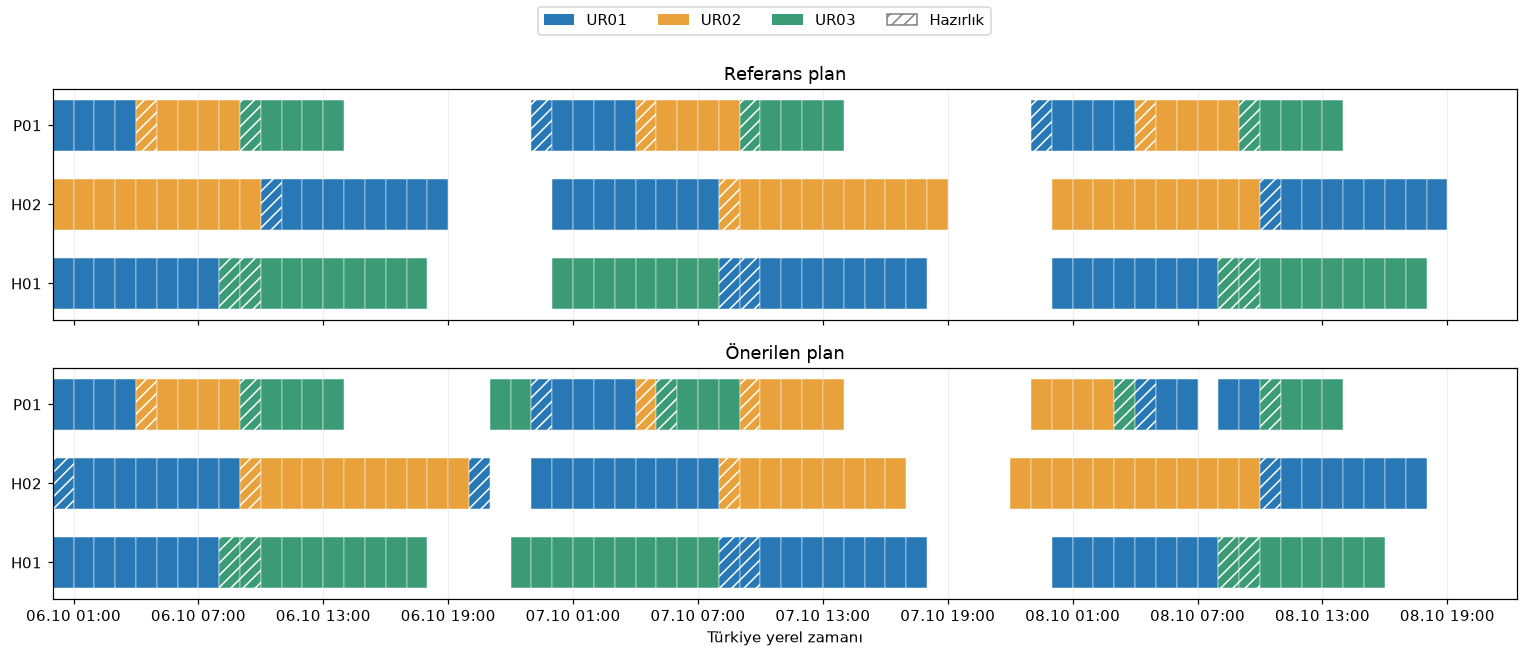

In [7]:
renkler = {"UR01": "#2878b5", "UR02": "#e9a23b", "UR03": "#3b9b76"}
kaynaklar = veriler["isletme_kurallari"]["kaynak_id"].tolist()
fig, eksenler = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, tablo, baslik in zip(eksenler,
                            [veriler["referans_plan"], plan],
                            ["Referans plan", "Önerilen plan"]):
    for i, kaynak in enumerate(kaynaklar):
        secim = tablo[(tablo["kaynak_id"] == kaynak) & (tablo["durum"] != "kapali")]
        for satir in secim.itertuples(index=False):
            ax.barh(i, 1/24, left=mdates.date2num(satir.tarih_saat), height=0.65,
                    color=renkler[satir.urun_id],
                    hatch="///" if satir.durum == "hazirlik" else None,
                    edgecolor="white", linewidth=0.3)
    ax.set_yticks(range(len(kaynaklar)), kaynaklar)
    ax.set_title(baslik)
    ax.grid(axis="x", alpha=0.2)
eksenler[-1].xaxis.set_major_locator(mdates.HourLocator(interval=6))
eksenler[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
eksenler[-1].set_xlabel("Türkiye yerel zamanı")
fig.legend(handles=[Patch(facecolor=c, label=p) for p, c in renkler.items()]
           + [Patch(facecolor="white", edgecolor="gray", hatch="///", label="Hazırlık")],
           loc="upper center", ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 5. Enerji profili ve teslimler

Enerji grafiği, faaliyetlerin saatler arasındaki dağılımını gösterir. Güç sınırı saatlik ortalama üzerinden değerlendirilir; anlık motor kalkış akımı bu modelin ölçtüğü büyüklük değildir.

Out[8]: 
          siparis_id  miktar_ton  ...          tamamlanma  zamaninda
0     SP1_UR01_dokme         720  ... 2025-10-06 16:00:00       True
1   SP1_UR01_torbali         320  ... 2025-10-06 12:00:00       True
2     SP1_UR02_dokme         400  ... 2025-10-06 12:00:00       True
3   SP1_UR02_torbali         400  ... 2025-10-06 15:00:00       True
4     SP1_UR03_dokme         160  ... 2025-10-06 17:00:00       True
5   SP1_UR03_torbali         240  ... 2025-10-06 17:00:00       True
6     SP2_UR01_dokme         720  ... 2025-10-07 17:00:00       True
7   SP2_UR01_torbali         320  ... 2025-10-07 11:00:00       True
8     SP2_UR02_dokme         400  ... 2025-10-07 12:00:00       True
9   SP2_UR02_torbali         400  ... 2025-10-07 15:00:00       True
10    SP2_UR03_dokme         160  ... 2025-10-07 11:00:00       True
11  SP2_UR03_torbali         240  ... 2025-10-07 17:00:00       True
12    SP3_UR01_dokme         720  ... 2025-10-08 17:00:00       True
13  SP3_UR01_torbali     

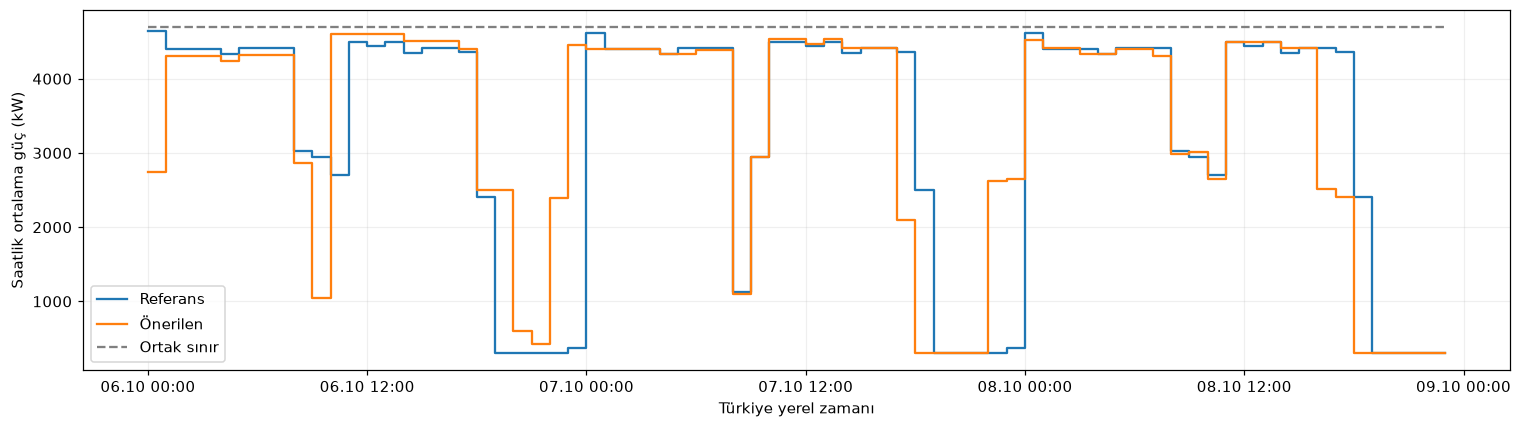

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.step(ref_saatlik["tarih_saat"], ref_saatlik["toplam_enerji_kwh"], where="post", label="Referans")
ax.step(saatlik["tarih_saat"], saatlik["toplam_enerji_kwh"], where="post", label="Önerilen")
ax.plot(veriler["tesis_takvimi"]["tarih_saat"],
        veriler["tesis_takvimi"]["guc_siniri_kw"], "--", color="gray", label="Ortak sınır")
ax.set_ylabel("Saatlik ortalama güç (kW)")
ax.set_xlabel("Türkiye yerel zamanı")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

teslim_ozeti = yuklemeler.groupby("siparis_id").agg(
    yuklenen_ton=("miktar_ton", "sum"), son_yukleme=("tarih_saat", "max")
)
teslim_ozeti["tamamlanma"] = teslim_ozeti["son_yukleme"] + pd.Timedelta(hours=1)
teslim_ozeti = veriler["siparisler"][["siparis_id", "miktar_ton", "teslim_zamani"]].merge(
    teslim_ozeti, on="siparis_id", validate="one_to_one"
)
teslim_ozeti["zamaninda"] = teslim_ozeti["tamamlanma"] <= teslim_ozeti["teslim_zamani"]
teslim_ozeti

## 6. Stok dengesi

Her ürünün dökme ve torbalı stokları ayrı izlenir. Çizelge kontrolü, saat başında tüketilebilecek malzemeyi ve saat sonundaki stok kapasitesini birlikte sınar.

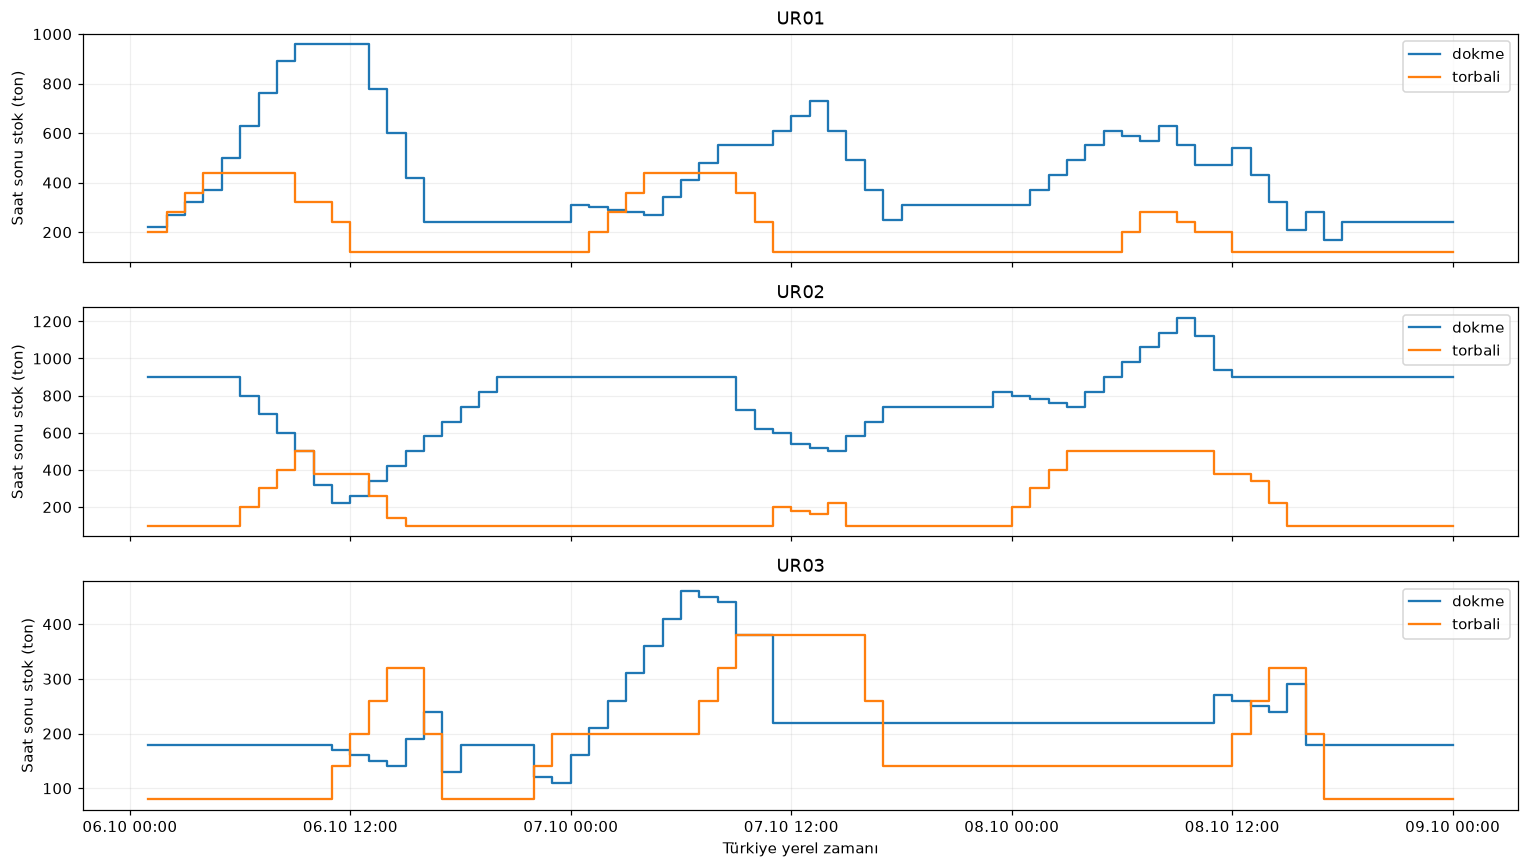

In [9]:
fig, eksenler = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, urun in zip(eksenler, veriler["urunler"]["urun_id"]):
    for tip in ["dokme", "torbali"]:
        secim = stok[(stok["urun_id"] == urun) & (stok["stok_turu"] == tip)]
        ax.step(secim["tarih_saat"] + pd.Timedelta(hours=1),
                secim["son_stok_ton"], where="post", label=tip)
    ax.set_title(urun)
    ax.set_ylabel("Saat sonu stok (ton)")
    ax.grid(alpha=0.2)
    ax.legend()
eksenler[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
eksenler[-1].set_xlabel("Türkiye yerel zamanı")
plt.tight_layout()
plt.show()

## 7. Değerlendirme çerçevesi

Maliyet farkı yalnızca tanımlı firma, üç günlük talep ve bilinen fiyatlar için geçerlidir. Üretim ve teslim miktarlarının korunması, enerji miktarının ve hazırlık sayısının karşılaştırılması sonucu yorumlamak için birlikte kullanılır. İyileşme bulunmaması, fiyat duyarlı planlamanın her durumda faydasız olduğunu göstermez; pozitif sonuç da her fabrikada aynı kazancı garanti etmez.

Model karma tamsayılı doğrusal programlama ile kurulmuş, HiGHS ile çözülmüştür. Küçük bir testte sonuç, 1.316 uygun alternatifin bağımsız hesaplandığı arama ile karşılaştırılır. Sabit fiyat ve yüksek plan değişikliği gideri testleri de uygulanır. Ana firma çözümü ayrıca çözücüden bağımsız stok ve faaliyet denetiminden geçirilir.

Yöntem ve varsayımlar: `docs/firma-cizelgeleme-yontemi.md`.